# COPC dataset and Laserchicken integration

This notebook extends the `copc-dataset` four-tile example. It uses the same deterministic uniformly sampled points as target points, reads full-resolution points from a 2 m halo around every Dask partition, and uses Laserchicken to calculate `mean_z` in a spherical target volume with radius 2 m. The enriched target cloud is rendered in XYZ space with a blue-white-red mean-height scale.

The halo is essential: target spheres near a Dask partition or COPC tile boundary must see points on both sides. Only targets owned by the disjoint core are returned, so every target is enriched exactly once.

## Imports and configuration

Run this notebook from the repository root with the `copc` Conda environment. `TARGETS_PER_SELECTION` defaults to the reference example's 200,000-point cap. Set `LC_TARGETS_PER_SELECTION` before starting Jupyter only when a smaller development run is desired. Targets are processed in user-defined **shards** of 5,000 points by default; `LC_TARGET_SHARD_SIZE` can lower that memory bound without changing results.

In [1]:
from __future__ import annotations

import json
import os
import zlib
from functools import partial
from itertools import combinations
from pathlib import Path

import duckdb
import laserchicken
import numpy as np
import pdal
import pyarrow as pa
import pyarrow.parquet as pq
import pyvista as pv
from distributed import Client, LocalCluster
from IPython.display import display
from laserchicken import compute_features, compute_neighborhoods
from laserchicken import kd_tree as lc_kd_tree
from laserchicken.volume_specification import Sphere
from PIL import Image as PILImage

from copc_dataset import DaskCopcExecutor, open_copc_dataset

REPOSITORY_ROOT = Path.cwd().resolve()
if not (REPOSITORY_ROOT / 'ahn5.parquet').exists():
    raise FileNotFoundError('Run this notebook from the UseCase_Ecology repository root')

CATALOG_PATH = REPOSITORY_ROOT / 'ahn5.parquet'
SPHERE_RADIUS = 2.0
TARGETS_PER_SELECTION = int(os.environ.get('LC_TARGETS_PER_SELECTION', '200000'))
TARGET_SHARD_SIZE = int(os.environ.get('LC_TARGET_SHARD_SIZE', '5000'))
EXPECTED_AOI_POINTS = 7_489_287
if TARGETS_PER_SELECTION < 1 or TARGET_SHARD_SIZE < 1:
    raise ValueError('Target and shard sizes must be positive')

print(f'Laserchicken: {laserchicken.__version__}')
print(f'Target cap per selection: {TARGETS_PER_SELECTION:,}')
print(f'Target shard size: {TARGET_SHARD_SIZE:,}')
print(f'Target-volume radius: {SPHERE_RADIUS:g} m')

Laserchicken: 0.8.1
Target cap per selection: 200,000
Target shard size: 5,000
Target-volume radius: 2 m


## Open the logical dataset and define core and halo selections

The 800 m by 800 m AoI is centered on the common corner of four AHN COPCs. Closed core bounds use `numpy.nextafter` at internal upper edges so ownership is non-overlapping. Halo selections overlap intentionally and extend 2 m beyond each core in X and Y.

In [2]:
dataset = open_copc_dataset(CATALOG_PATH)
AOI_CENTER = (126_000.0, 486_000.0)
AOI_X = (125_600.0, 126_400.0)
AOI_Y = (485_600.0, 486_400.0)
GRID_COLUMNS = 3
GRID_ROWS = 2
X_NAMES = ('west', 'center', 'east')
Y_NAMES = ('south', 'north')
READ_COLUMNS = (
    'X', 'Y', 'Z', 'Classification', 'GpsTime', 'PointSourceId', 'ReturnNumber'
)

complete_aoi = dataset.selection('four-tile-aoi', x=AOI_X, y=AOI_Y, z=None)
assert len(dataset.candidate_sources(complete_aoi)) == 4
print(dataset)
print('AOI candidate COPCs:', [s.id for s in dataset.candidate_sources(complete_aoi)])

<CopcDataset>
  Sources: 9
  Points: 227,097,911
  X: [124000.0, 126999.999]
  Y: [484000.0, 486999.999]
  Z: [-6.606, 86.915]
  Dimensions: X: double, Y: double, Z: double, Intensity: uint16, ReturnNumber: uint8, NumberOfReturns: uint8, ScanDirectionFlag: uint8, EdgeOfFlightLine: uint8, Classification: uint8, Synthetic: uint8, KeyPoint: uint8, Withheld: uint8, Overlap: uint8, ScanAngleRank: float, UserData: uint8, PointSourceId: uint16, GpsTime: double, ScanChannel: uint8
  CRS: Amersfoort / RD New + NAP height
AOI candidate COPCs: ['AHN5_C_125000_485000.COPC', 'AHN5_C_125000_486000.COPC', 'AHN5_C_126000_485000.COPC', 'AHN5_C_126000_486000.COPC']


In [3]:
x_edges = np.linspace(AOI_X[0], AOI_X[1], GRID_COLUMNS + 1)
y_edges = np.linspace(AOI_Y[0], AOI_Y[1], GRID_ROWS + 1)
cores = []
halos = []
core_bounds_by_halo_id = {}

for row in range(GRID_ROWS):
    for column in range(GRID_COLUMNS):
        core_id = f'{Y_NAMES[row]}-{X_NAMES[column]}'
        max_x = (
            x_edges[column + 1]
            if column == GRID_COLUMNS - 1
            else np.nextafter(x_edges[column + 1], -np.inf)
        )
        max_y = (
            y_edges[row + 1]
            if row == GRID_ROWS - 1
            else np.nextafter(y_edges[row + 1], -np.inf)
        )
        core = dataset.selection(
            core_id,
            x=(x_edges[column], max_x),
            y=(y_edges[row], max_y),
            z=None,
            columns=READ_COLUMNS,
        )
        halo_id = f'{core_id}-halo-{SPHERE_RADIUS:g}m'
        halo = dataset.selection(
            halo_id,
            x=(core.bounds.min_x - SPHERE_RADIUS, core.bounds.max_x + SPHERE_RADIUS),
            y=(core.bounds.min_y - SPHERE_RADIUS, core.bounds.max_y + SPHERE_RADIUS),
            z=None,
            columns=READ_COLUMNS,
        )
        cores.append(core)
        halos.append(halo)
        core_bounds_by_halo_id[halo_id] = (
            core.id,
            core.bounds.min_x, core.bounds.max_x,
            core.bounds.min_y, core.bounds.max_y,
        )

cores = tuple(cores)
halos = tuple(halos)
assert len(cores) == 6
assert all(not a.bounds.intersects(b.bounds) for a, b in combinations(cores, 2))
display([
    {
        'core': core.id,
        'core_xy': (core.bounds.min_x, core.bounds.max_x, core.bounds.min_y, core.bounds.max_y),
        'halo_xy': (halo.bounds.min_x, halo.bounds.max_x, halo.bounds.min_y, halo.bounds.max_y),
    }
    for core, halo in zip(cores, halos)
])

[{'core': 'south-west',
  'core_xy': (125600.0, 125866.66666666666, 485600.0, 485999.99999999994),
  'halo_xy': (125598.0, 125868.66666666666, 485598.0, 486001.99999999994)},
 {'core': 'south-center',
  'core_xy': (125866.66666666667,
   126133.33333333331,
   485600.0,
   485999.99999999994),
  'halo_xy': (125864.66666666667,
   126135.33333333331,
   485598.0,
   486001.99999999994)},
 {'core': 'south-east',
  'core_xy': (126133.33333333333, 126400.0, 485600.0, 485999.99999999994),
  'halo_xy': (126131.33333333333, 126402.0, 485598.0, 486001.99999999994)},
 {'core': 'north-west',
  'core_xy': (125600.0, 125866.66666666666, 486000.0, 486400.0),
  'halo_xy': (125598.0, 125868.66666666666, 485998.0, 486402.0)},
 {'core': 'north-center',
  'core_xy': (125866.66666666667, 126133.33333333331, 486000.0, 486400.0),
  'halo_xy': (125864.66666666667, 126135.33333333331, 485998.0, 486402.0)},
 {'core': 'north-east',
  'core_xy': (126133.33333333333, 126400.0, 486000.0, 486400.0),
  'halo_xy': (

## Worker-side sampling and Laserchicken enrichment

The processor consumes each halo stream once. All halo XYZ points form the Laserchicken environment cloud; only core-owned rows participate in deterministic target sampling. Stable priorities are identical to the reference notebook because they use the same seven attributes and the original core ID.

Laserchicken first uses an XY KD-tree and then applies the exact 3D sphere test. Its `mean_z` feature is the arithmetic mean of source elevations in the sphere. Target processing is explicitly divided into bounded **shards**. The full-resolution environment KD-tree is retained, while each shard's target tree and nested neighborhood lists are discarded before the next shard. Eight targets per partition are checked independently using direct 3D squared distances.

In [4]:
def stable_point_priorities(arrays, selection_id):
    """Return the reference example's deterministic point priorities."""
    seed = np.uint64(zlib.crc32(selection_id.encode('utf-8')))
    priorities = np.full(
        arrays['X'].size,
        np.uint64(1_469_598_103_934_665_603) ^ seed,
        dtype=np.uint64,
    )
    fnv_prime = np.uint64(1_099_511_628_211)
    for name in ('X', 'Y', 'Z', 'GpsTime'):
        values = np.ascontiguousarray(arrays[name], dtype=np.float64).view(np.uint64)
        priorities ^= values
        priorities *= fnv_prime
    for name in ('Classification', 'PointSourceId', 'ReturnNumber'):
        values = np.asarray(arrays[name], dtype=np.uint64)
        priorities ^= values
        priorities *= fnv_prime
    priorities ^= priorities >> np.uint64(30)
    priorities *= np.uint64(13_765_031_520_994_252_897)
    priorities ^= priorities >> np.uint64(27)
    priorities *= np.uint64(10_723_178_051_746_563_781)
    priorities ^= priorities >> np.uint64(31)
    return priorities


def as_laserchicken_cloud(points):
    """Build Laserchicken's in-memory point-cloud representation."""
    return {
        'vertex': {
            name.lower(): {'type': 'float64', 'data': points[:, index]}
            for index, name in enumerate(('X', 'Y', 'Z'))
        }
    }


def retain_only_environment_tree():
    """Drop cached target trees while retaining the first environment tree."""
    x_refs, y_refs, trees = lc_kd_tree.kd_tree_cache
    lc_kd_tree.kd_tree_cache = ([x_refs[0]], [y_refs[0]], [trees[0]])


def enrich_halo_selection(
    batches, selection, dataset_metadata, *,
    core_bounds, radius, max_targets, target_shard_size
):
    """Sample core targets and calculate full-resolution spherical mean Z."""
    del dataset_metadata
    core_id, min_x, max_x, min_y, max_y = core_bounds[selection.id]
    environment_chunks = []
    priorities = np.empty(0, dtype=np.uint64)
    target_points = np.empty((0, 3), dtype=np.float64)
    target_classes = np.empty(0, dtype=np.uint8)
    core_point_count = 0

    for batch in batches:
        arrays = {
            name: batch[name].to_numpy(zero_copy_only=False)
            for name in READ_COLUMNS
        }
        environment_chunks.append(
            np.column_stack((arrays['X'], arrays['Y'], arrays['Z'])).astype(
                np.float64, copy=False
            )
        )
        in_core = (
            (arrays['X'] >= min_x) & (arrays['X'] <= max_x)
            & (arrays['Y'] >= min_y) & (arrays['Y'] <= max_y)
        )
        if not np.any(in_core):
            continue

        core_arrays = {name: values[in_core] for name, values in arrays.items()}
        core_point_count += core_arrays['X'].size
        batch_points = np.column_stack(
            (core_arrays['X'], core_arrays['Y'], core_arrays['Z'])
        ).astype(np.float64, copy=False)
        candidate_priorities = np.concatenate(
            (priorities, stable_point_priorities(core_arrays, core_id))
        )
        candidate_points = np.concatenate((target_points, batch_points), axis=0)
        candidate_classes = np.concatenate(
            (target_classes, np.asarray(core_arrays['Classification'], dtype=np.uint8))
        )
        if candidate_priorities.size > max_targets:
            keep = np.argpartition(candidate_priorities, max_targets - 1)[:max_targets]
            priorities = candidate_priorities[keep]
            target_points = candidate_points[keep]
            target_classes = candidate_classes[keep]
        else:
            priorities = candidate_priorities
            target_points = candidate_points
            target_classes = candidate_classes

    environment_points = np.concatenate(environment_chunks, axis=0)
    environment_chunks.clear()
    del priorities
    environment_cloud = as_laserchicken_cloud(environment_points)
    volume = Sphere(radius)
    mean_z = np.empty(target_points.shape[0], dtype=np.float64)
    target_shard_count = 0

    lc_kd_tree.initialize_cache()
    try:
        lc_kd_tree.get_kdtree_for_pc(environment_cloud)
        for shard_start in range(0, target_points.shape[0], target_shard_size):
            shard_end = min(shard_start + target_shard_size, target_points.shape[0])
            target_shard = as_laserchicken_cloud(target_points[shard_start:shard_end])
            neighborhoods = compute_neighborhoods(
                environment_cloud, target_shard, volume
            )
            compute_features(
                environment_cloud,
                neighborhoods,
                target_shard,
                ['mean_z'],
                volume,
                verbose=False,
            )
            mean_z[shard_start:shard_end] = (
                target_shard['vertex']['mean_z']['data']
            )
            target_shard_count += 1
            retain_only_environment_tree()
    finally:
        lc_kd_tree.initialize_cache()

    verification_errors = []
    for target in target_points[: min(8, target_points.shape[0])]:
        squared_distances = np.sum((environment_points - target) ** 2, axis=1)
        direct_mean = environment_points[squared_distances <= radius**2, 2].mean()
        verification_errors.append(direct_mean)
    direct_means = np.asarray(verification_errors)
    max_verification_error = (
        float(np.max(np.abs(mean_z[: direct_means.size] - direct_means)))
        if direct_means.size
        else 0.0
    )

    return {
        'selection_id': core_id,
        'core_point_count': core_point_count,
        'environment_point_count': environment_points.shape[0],
        'points': target_points,
        'classification': target_classes,
        'mean_z': mean_z,
        'target_shard_count': target_shard_count,
        'max_verification_error': max_verification_error,
    }

## Execute the six core-halo jobs with Dask

Two worker processes bound concurrent COPC reads and run two Laserchicken jobs at a time. Within each worker, target shards are processed sequentially against one retained environment KD-tree. The DuckDB PDAL extension is installed once before the workers load it.

In [5]:
connection = duckdb.connect(database=':memory:')
try:
    connection.execute('INSTALL pdal FROM community')
finally:
    connection.close()

processor = partial(
    enrich_halo_selection,
    core_bounds=core_bounds_by_halo_id,
    radius=SPHERE_RADIUS,
    max_targets=TARGETS_PER_SELECTION,
    target_shard_size=TARGET_SHARD_SIZE,
)
cluster = LocalCluster(
    n_workers=2,
    threads_per_worker=1,
    processes=True,
    dashboard_address=None,
)
client = Client(cluster)
try:
    executor = DaskCopcExecutor(
        client,
        reader_options={
            'requests': 2,
            'batch_size': 65_536,
            'install_extension': False,
        },
    )
    futures = executor.submit(dataset, halos, processor=processor)
    results = {halo_id: future.result() for halo_id, future in futures.items()}
finally:
    client.close()
    cluster.close()

print('Completed', len(results), 'Laserchicken jobs')

Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequ

 ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree cre

/Users/mwgrootes/miniforge3/envs/copc/lib/python3.12/site-packages/laserchicken/feature_extractor/mean_std_coeff_feature_extractor.py:28: RuntimeWarning: divide by zero encountered in scalar divide
  coeff_var_z = std_z / mean_z


Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequ

 ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree cre

 ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree creation
The following unrequested features were calculated as a side effect, but will not be returned: ['coeff_var_z', 'std_z']
Cylinder size in Bytes: 271433605.2701581
Memory size in Bytes: 17179869184
Start tree creation
Done with env tree creation
Done with target tree cre

Completed 6 Laserchicken jobs


## Validate and combine the enriched targets

In [6]:
ordered_results = [results[halo.id] for halo in halos]
summary = [
    {
        'selection': result['selection_id'],
        'core_points': result['core_point_count'],
        'halo_points': result['environment_point_count'],
        'targets': result['points'].shape[0],
        'target_shards': result['target_shard_count'],
        'mean_z_min': float(np.min(result['mean_z'])),
        'mean_z_max': float(np.max(result['mean_z'])),
        'verification_error': result['max_verification_error'],
    }
    for result in ordered_results
]
display(summary)

core_point_count = sum(result['core_point_count'] for result in ordered_results)
target_points = np.concatenate([result['points'] for result in ordered_results], axis=0)
target_classes = np.concatenate(
    [result['classification'] for result in ordered_results], axis=0
)
target_mean_z = np.concatenate([result['mean_z'] for result in ordered_results])

assert core_point_count == EXPECTED_AOI_POINTS
assert target_points.shape[0] == sum(
    min(TARGETS_PER_SELECTION, result['core_point_count'])
    for result in ordered_results
)
assert np.all(np.isfinite(target_mean_z))
assert max(result['max_verification_error'] for result in ordered_results) < 1e-12
assert np.all(np.abs(target_mean_z - target_points[:, 2]) <= SPHERE_RADIUS)

print(f'Complete AoI points counted: {core_point_count:,}')
print(f'Enriched target points: {target_points.shape[0]:,}')
print(f'Mean-Z range: {target_mean_z.min():.3f} to {target_mean_z.max():.3f} m NAP')
print(f'Max independent verification error: {max(r["max_verification_error"] for r in ordered_results):.3g}')

[{'selection': 'south-west',
  'core_points': 2268762,
  'halo_points': 2314432,
  'targets': 200000,
  'target_shards': 40,
  'mean_z_min': -3.1570065075921905,
  'mean_z_max': 32.943923913043484,
  'verification_error': 0.0},
 {'selection': 'south-center',
  'core_points': 194473,
  'halo_points': 206770,
  'targets': 194473,
  'target_shards': 39,
  'mean_z_min': -0.634,
  'mean_z_max': 18.389611570247936,
  'verification_error': 0.0},
 {'selection': 'south-east',
  'core_points': 909097,
  'halo_points': 941846,
  'targets': 200000,
  'target_shards': 40,
  'mean_z_min': -0.5454285714285714,
  'mean_z_max': 32.172666666666665,
  'verification_error': 0.0},
 {'selection': 'north-west',
  'core_points': 676090,
  'halo_points': 706705,
  'targets': 200000,
  'target_shards': 40,
  'mean_z_min': -0.855,
  'mean_z_max': 23.435333333333332,
  'verification_error': 0.0},
 {'selection': 'north-center',
  'core_points': 2665935,
  'halo_points': 2718729,
  'targets': 200000,
  'target_shar

Complete AoI points counted: 7,489,287
Enriched target points: 1,194,473
Mean-Z range: -3.157 to 37.546 m NAP
Max independent verification error: 0


## Plot the enriched target point cloud

Points retain their original X, Y, and Z coordinates. Colors are clipped at the 1st and 99th mean-height percentiles so outliers do not flatten the blue-white-red contrast; the scalar bar reports elevation relative to NAP.

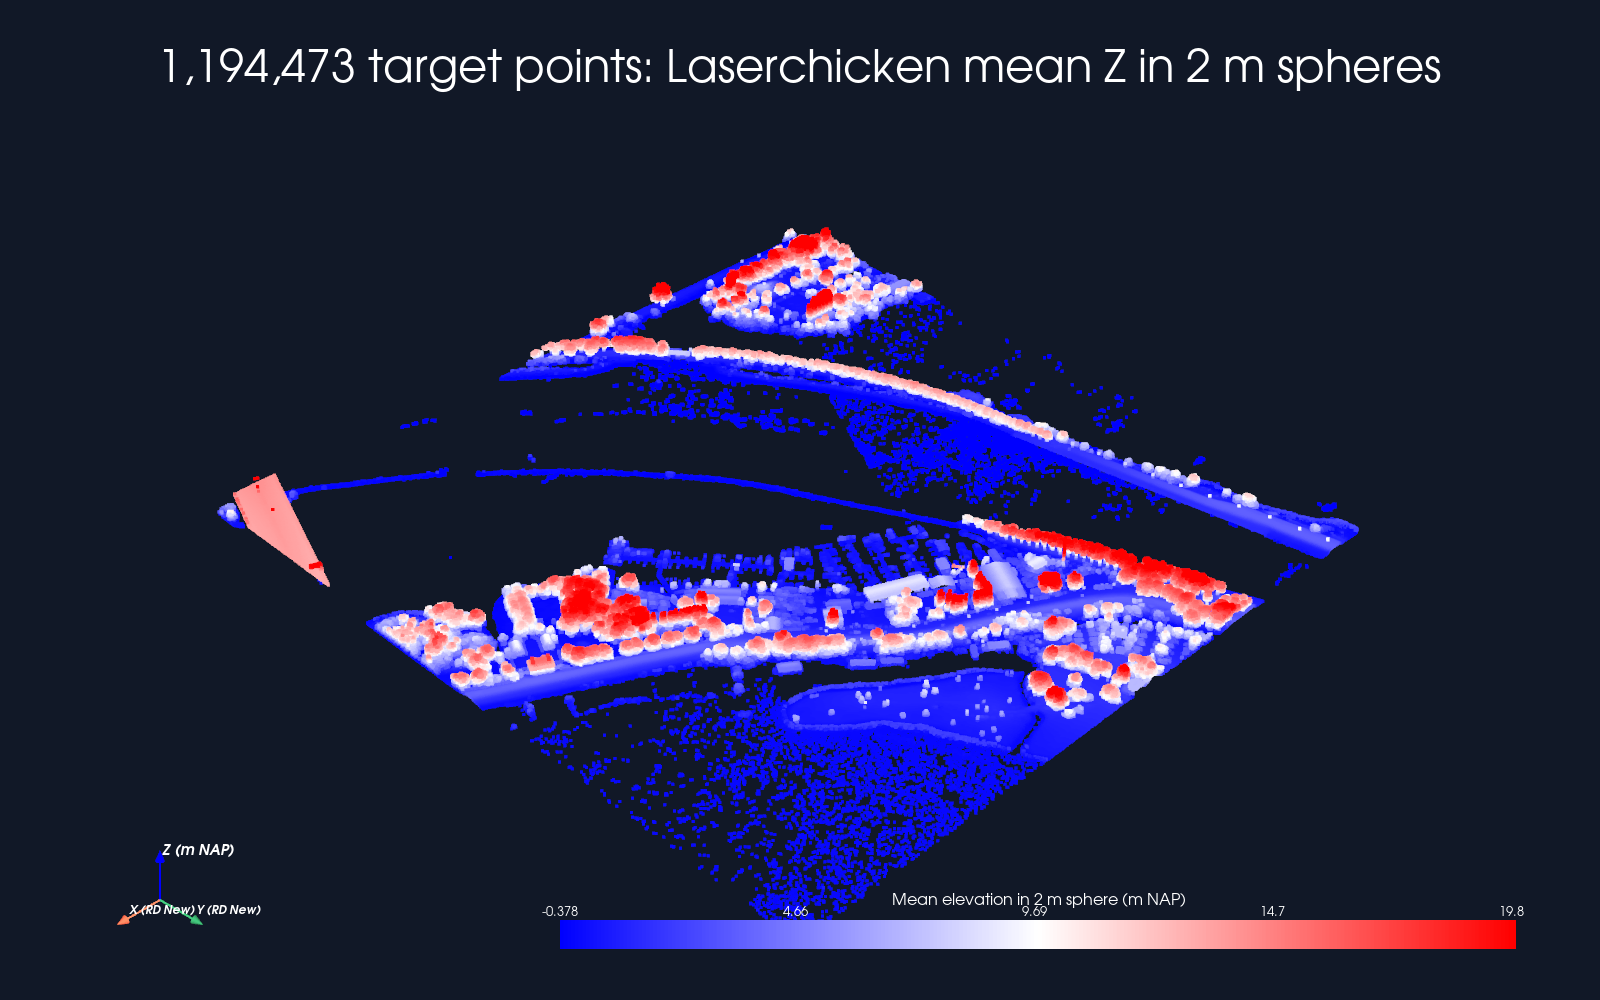

In [7]:
color_limits = tuple(np.quantile(target_mean_z, [0.01, 0.99]))
cloud = pv.PolyData(target_points)
cloud['mean_z'] = target_mean_z

plotter = pv.Plotter(off_screen=True, window_size=(1600, 1000))
plotter.set_background('#111827')
plotter.add_mesh(
    cloud,
    scalars='mean_z',
    cmap='bwr',
    clim=color_limits,
    point_size=2.5,
    render_points_as_spheres=False,
    scalar_bar_args={
        'title': 'Mean elevation in 2 m sphere (m NAP)',
        'color': 'white',
        'title_font_size': 16,
        'label_font_size': 13,
    },
)
plotter.add_axes(
    xlabel='X (RD New)', ylabel='Y (RD New)', zlabel='Z (m NAP)', color='white'
)
plotter.add_title(
    f'{target_points.shape[0]:,} target points: Laserchicken mean Z in 2 m spheres',
    color='white',
)
plotter.camera_position = 'iso'
plotter.camera.zoom(1.2)
image = plotter.screenshot(return_img=True)
plotter.close()
display(PILImage.fromarray(image))

## Result

The target cloud is a bounded-memory deterministic uniform sample, while each `mean_z` value uses all full-resolution COPC points in its 2 m sphere. Core ownership prevents duplicate targets and halo reads remove artificial feature discontinuities at Dask partition and COPC tile boundaries. The cells below persist those core-owned enriched targets as a reusable COPC collection.

## Write the enriched sphere targets as a COPC collection

Each spatial core becomes one lowercase `.copc.laz` file. Target shards remain an internal memory-management detail and are recombined before writing. `MeanZ` is stored as a `float32` LAS Extra Bytes dimension, while target XYZ and classification are preserved. A relative-path STAC-style Parquet catalog allows the collection to be reopened with `copc-dataset`.

In [8]:
SPHERE_COPC_DIRECTORY = REPOSITORY_ROOT / 'outputs' / 'sphere_mean_z_copc'
SPHERE_CATALOG_PATH = SPHERE_COPC_DIRECTORY / 'sphere_mean_z_catalog.parquet'
SPHERE_COPC_DIRECTORY.mkdir(parents=True, exist_ok=True)


def write_sphere_result_copc(result, output_path):
    """Write one core's enriched target points as COPC."""
    point_count = result['points'].shape[0]
    array = np.empty(
        point_count,
        dtype=[
            ('X', '<f8'), ('Y', '<f8'), ('Z', '<f8'),
            ('Classification', 'u1'), ('MeanZ', '<f4'),
        ],
    )
    array['X'], array['Y'], array['Z'] = result['points'].T
    array['Classification'] = result['classification']
    array['MeanZ'] = result['mean_z'].astype(np.float32)
    writer = {
        'type': 'writers.copc',
        'filename': str(output_path),
        'a_srs': dataset.crs.to_wkt(),
        'extra_dims': 'all',
        'scale_x': 0.001, 'scale_y': 0.001, 'scale_z': 0.001,
        'offset_x': 'auto', 'offset_y': 'auto', 'offset_z': 'auto',
        'software_id': 'copc-dataset + laserchicken',
        'pdal_metadata': True,
        'threads': 2,
    }
    written = pdal.Pipeline(json.dumps([writer]), arrays=[array]).execute()
    assert written == point_count
    return output_path


def sphere_catalog_row(result, output_path):
    points = result['points']
    minimum = points.min(axis=0)
    maximum = points.max(axis=0)
    return {
        'id': result['selection_id'],
        'assets': {'data': {'href': output_path.name, 'type': 'application/vnd.laszip+copc'}},
        'pc:count': points.shape[0],
        'pc:schemas': [
            {'name': 'X', 'size': 8, 'type': 'floating'},
            {'name': 'Y', 'size': 8, 'type': 'floating'},
            {'name': 'Z', 'size': 8, 'type': 'floating'},
            {'name': 'Classification', 'size': 1, 'type': 'unsigned'},
            {'name': 'MeanZ', 'size': 4, 'type': 'floating'},
        ],
        'proj:bbox': [*minimum.tolist(), *maximum.tolist()],
        'proj:wkt2': dataset.crs.to_wkt(),
        'properties': {
            'processing:target_volume': 'sphere',
            'processing:radius': SPHERE_RADIUS,
            'processing:feature': 'MeanZ',
            'processing:laserchicken_version': laserchicken.__version__,
        },
    }

In [9]:
for old_path in SPHERE_COPC_DIRECTORY.glob('*.copc.laz'):
    old_path.unlink()

sphere_copc_paths = []
sphere_catalog_rows = []
for result in ordered_results:
    output_path = SPHERE_COPC_DIRECTORY / f"{result['selection_id']}.copc.laz"
    sphere_copc_paths.append(write_sphere_result_copc(result, output_path))
    sphere_catalog_rows.append(sphere_catalog_row(result, output_path))

pq.write_table(pa.Table.from_pylist(sphere_catalog_rows), SPHERE_CATALOG_PATH)
sphere_output_dataset = open_copc_dataset(SPHERE_CATALOG_PATH)
assert sphere_output_dataset.source_count == len(ordered_results)
assert sphere_output_dataset.point_count == target_points.shape[0]
assert sphere_output_dataset.dimensions == ('X', 'Y', 'Z', 'Classification', 'MeanZ')

display({
    'catalog': str(SPHERE_CATALOG_PATH),
    'copc_files': len(sphere_copc_paths),
    'points': sphere_output_dataset.point_count,
    'dimensions': sphere_output_dataset.dimensions,
    'bytes': sum(path.stat().st_size for path in sphere_copc_paths),
})

{'catalog': '/Users/mwgrootes/Projects/REPOS/HPC-DAT/UseCase_Ecology/outputs/sphere_mean_z_copc/sphere_mean_z_catalog.parquet',
 'copc_files': 6,
 'points': 1194473,
 'dimensions': ('X', 'Y', 'Z', 'Classification', 'MeanZ'),
 'bytes': 11729390}